# EDA + מבחנים סטטיסטיים — פיצ'רי ה-ML משלב 1

לכל שלב הכנת-הפיצ'רים ב-`01_prep_clean.ipynb` (סעיפים 8-11) — **גרף** + **מבחן סטטיסטי פורמלי** (לא רק תיאור חזותי):

1. **חוסר נתונים** — מבחן Chi-Square: האם החוסר ב-ORIGIN_CALL/ORIGIN_STAND תלוי ב-CALL_TYPE (MNAR)?
2. **חריגים** — Box plots גולמי מול Winsorized + ספירת חריגים לפי כלל 1.5×IQR
3. **טרנספורמציות** — היסטוגרמות + Skewness/Kurtosis + מבחני נורמליות (D'Agostino, Shapiro) לכל גרסה (גולמי/winsorized/log/sqrt)
4. **קידוד** — התפלגות CALL_TYPE, ORIGIN_STAND_grouped, TAXI_ID_freq (+ בדיקת Pareto)
5. **חוסר איזון DAY_TYPE** — גרף + משקלי מחלקה
6. בונוס: מטריצת קורלציה בין פיצ'רי המסלול

מריצים **אחרי** `01_prep_clean.ipynb` (טוען את `out/trips_clean_sample.parquet`).


## 0. טעינה

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from pyspark.sql import SparkSession

FIG_DIR = "out/figs"
os.makedirs(FIG_DIR, exist_ok=True)
sns.set_theme(style="whitegrid")

spark = (SparkSession.builder.appName("porto-taxi-eda").master("local[*]")
         .config("spark.driver.memory", "4g").getOrCreate())
spark.sparkContext.setLogLevel("WARN")

sdf = spark.read.parquet("out/trips_clean_sample.parquet")
cols = [
    "TRIP_ID", "CALL_TYPE", "ORIGIN_CALL", "ORIGIN_STAND", "DAY_TYPE",
    "distance_km", "distance_km_wins", "distance_km_log", "distance_km_sqrt",
    "duration_sec", "duration_sec_wins", "duration_sec_log", "duration_sec_sqrt",
    "avg_kmh", "avg_kmh_wins",
    "n_points", "TAXI_ID_freq", "ORIGIN_STAND_grouped", "ORIGIN_STAND_freq",
    "ORIGIN_CALL_filled", "class_weight",
]
df = sdf.select(*cols).toPandas()
print("rows:", len(df))


## 1. חוסר נתונים — מבחן Chi-Square

בודקים פורמלית את ההחלטה משלב 1 בצינור: שהחוסר ב-`ORIGIN_CALL`/`ORIGIN_STAND` **תלוי** ב-`CALL_TYPE` (MNAR) ולא אקראי — מה שמצדיק קידוד "Not_Applicable" במקום מחיקה.

In [2]:
def missing_chisq(df, target_col, label):
    is_missing = df[target_col].isnull()
    ct = pd.crosstab(df["CALL_TYPE"], is_missing)
    chi2, p, dof, _ = stats.chi2_contingency(ct)
    print(f"[{label}] missingness vs CALL_TYPE  chi2={chi2:.1f}  dof={dof}  p={p:.3e}")
    print(ct)
    return ct, chi2, p

ct_call, chi2_call, p_call = missing_chisq(df, "ORIGIN_CALL", "ORIGIN_CALL")
ct_stand, chi2_stand, p_stand = missing_chisq(df, "ORIGIN_STAND", "ORIGIN_STAND")


[ORIGIN_CALL] missingness vs CALL_TYPE  chi2=17883.0  dof=2  p=0.000e+00
ORIGIN_CALL  False  True 
CALL_TYPE                
A             4066      0
B                0   9247
C                0   4570
[ORIGIN_STAND] missingness vs CALL_TYPE  chi2=17428.5  dof=2  p=0.000e+00
ORIGIN_STAND  False  True 
CALL_TYPE                 
A                 0   4066
B              9132    115
C                 0   4570


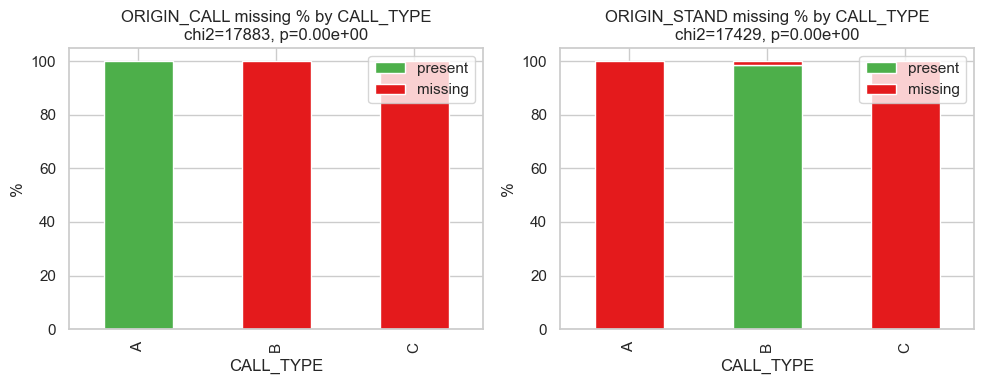

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
(ct_call.div(ct_call.sum(1), axis=0) * 100).plot.bar(stacked=True, ax=ax[0], color=["#4daf4a", "#e41a1c"])
ax[0].set_title(f"ORIGIN_CALL missing % by CALL_TYPE\nchi2={chi2_call:.0f}, p={p_call:.2e}")
ax[0].set_ylabel("%"); ax[0].legend(["present", "missing"])
(ct_stand.div(ct_stand.sum(1), axis=0) * 100).plot.bar(stacked=True, ax=ax[1], color=["#4daf4a", "#e41a1c"])
ax[1].set_title(f"ORIGIN_STAND missing % by CALL_TYPE\nchi2={chi2_stand:.0f}, p={p_stand:.2e}")
ax[1].set_ylabel("%"); ax[1].legend(["present", "missing"])
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/01_missing_chisq.png", dpi=120); plt.show()


**מסקנה:** p-value≈0 בשני המבחנים → דוחים את השערת האפס (אי-תלות). החוסר הוא **Missing Not At Random**, נקבע ב-100% ע"י CALL_TYPE — מאשר שמילוי בקטגוריה ("0"/"Not_Applicable") נכון יותר ממחיקה.

## 2. חריגים — Box Plots גולמי מול Winsorized + מבחן IQR

`distance_km`, `duration_sec`, `avg_kmh` — לפני ואחרי חיתוך לאחוזון 95.

In [4]:
def iqr_outlier_stats(s, label):
    q1, q3 = s.quantile(.25), s.quantile(.75)
    iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = ((s < lo) | (s > hi)).sum()
    print(f"  {label}: IQR=[{q1:.2f},{q3:.2f}] fence=({lo:.2f},{hi:.2f}) outliers={n_out} ({100*n_out/len(s):.2f}%)")
    return n_out

pairs = [("distance_km", "distance_km_wins"), ("duration_sec", "duration_sec_wins"),
         ("avg_kmh", "avg_kmh_wins")]

outlier_rows = []
for raw, wins in pairs:
    print(f"{raw}:")
    n_raw = iqr_outlier_stats(df[raw], "raw")
    n_wins = iqr_outlier_stats(df[wins], "winsorized")
    outlier_rows.append({"variable": raw, "outliers_raw": n_raw, "outliers_winsorized": n_wins})

outlier_df = pd.DataFrame(outlier_rows)
outlier_df


distance_km:
  raw: IQR=[2.36,6.39] fence=(-3.69,12.44) outliers=1292 (7.22%)
  winsorized: IQR=[2.36,6.39] fence=(-3.69,12.44) outliers=1292 (7.22%)
duration_sec:
  raw: IQR=[405.00,840.00] fence=(-247.50,1492.50) outliers=729 (4.08%)
  winsorized: IQR=[405.00,840.00] fence=(-247.50,1492.50) outliers=0 (0.00%)
avg_kmh:
  raw: IQR=[18.18,31.99] fence=(-2.53,52.70) outliers=1018 (5.69%)
  winsorized: IQR=[18.18,31.99] fence=(-2.53,52.70) outliers=1018 (5.69%)


,variable,outliers_raw,outliers_winsorized
0,distance_km,1292,1292
1,duration_sec,729,0
2,avg_kmh,1018,1018


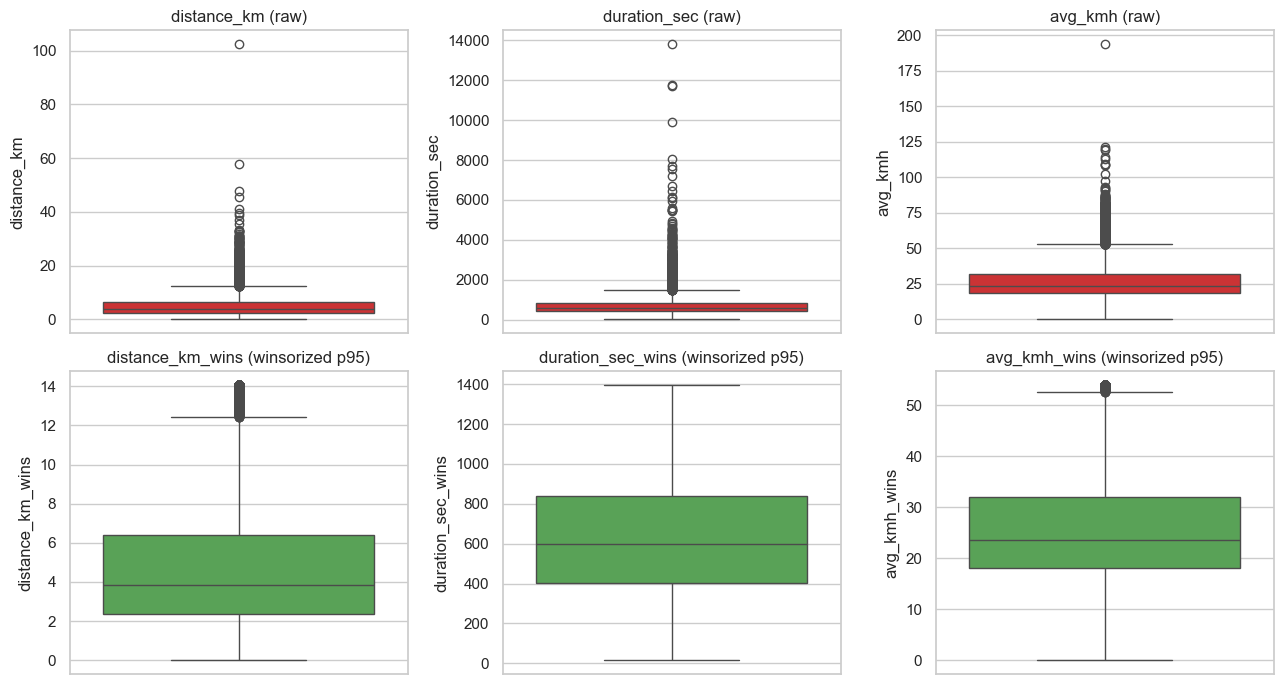

In [5]:
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for i, (raw, wins) in enumerate(pairs):
    sns.boxplot(y=df[raw], ax=axes[0, i], color="#e41a1c"); axes[0, i].set_title(f"{raw} (raw)")
    sns.boxplot(y=df[wins], ax=axes[1, i], color="#4daf4a"); axes[1, i].set_title(f"{wins} (winsorized p95)")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/02_boxplots_winsorize.png", dpi=120); plt.show()


**הערה מתודולוגית חשובה:** ב-`distance_km`/`avg_kmh` מספר החריגים לפי כלל 1.5×IQR **לא השתנה** אחרי Winsorizing — כי הגדר של Tukey (1.5×IQR) הדוק בהרבה מהחיתוך לאחוזון 95. Winsorizing לא "מבטל" חריגים סטטיסטיים, הוא רק **גובל את הגודל הקיצוני שלהם** (כל הערכים שמעל p95 מקובצים לערך אחד) — רואים זאת ב-Box plot כתיבה (whisker) קצרה בהרבה למרות שעדיין יש חריגים.

## 3. טרנספורמציות — היסטוגרמות + Skewness/Kurtosis + מבחני נורמליות

לכל גרסה (גולמי / winsorized / log / sqrt): סקיוּ, קורטוזיס, ומבחנים פורמליים —
**skewtest**, **normaltest** (D'Agostino-Pearson, תקף לכל n) ו-**Shapiro-Wilk** (על מדגם של 5000, כי תקף עד n≈5000).

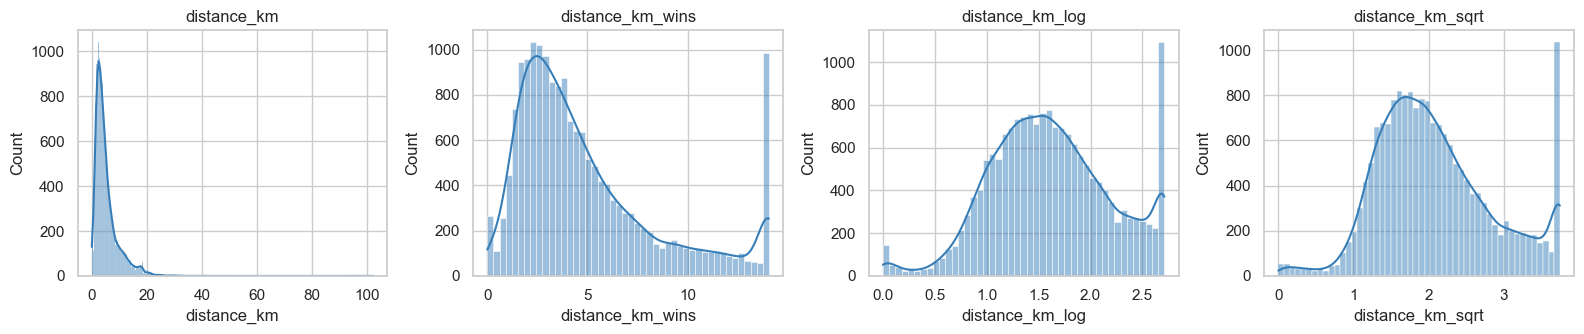

distance_km:
  distance_km            skew=  2.701 kurt= 20.719  skewtest p=0.00e+00  normaltest p=0.00e+00  shapiro(n=5000) p=8.73e-62
  distance_km_wins       skew=  1.190 kurt=  0.597  skewtest p=0.00e+00  normaltest p=0.00e+00  shapiro(n=5000) p=3.28e-54
  distance_km_log        skew=  0.032 kurt= -0.277  skewtest p=7.97e-02  normaltest p=3.86e-18  shapiro(n=5000) p=2.22e-24
  distance_km_sqrt       skew=  0.451 kurt= -0.144  skewtest p=1.36e-122  normaltest p=5.53e-125  shapiro(n=5000) p=4.90e-34


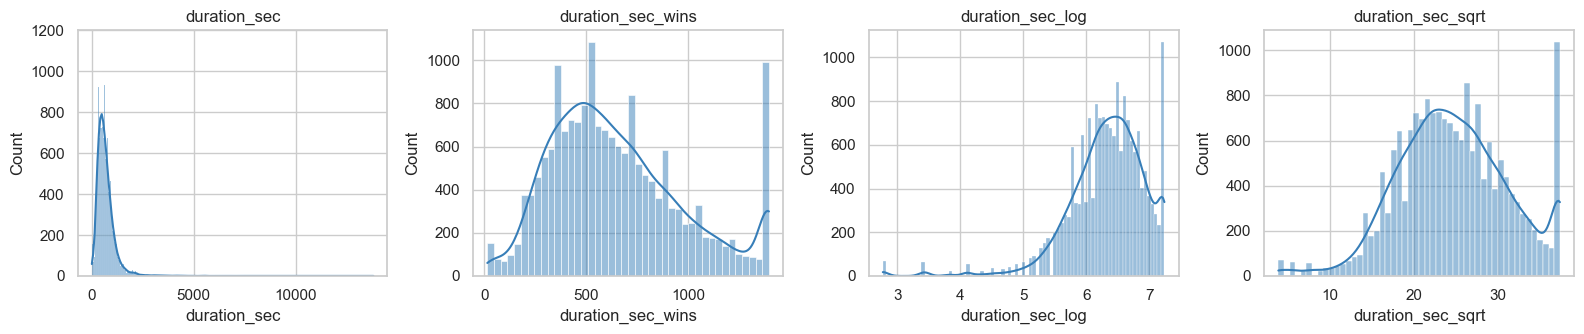

duration_sec:
  duration_sec           skew=  5.906 kurt= 91.487  skewtest p=0.00e+00  normaltest p=0.00e+00  shapiro(n=5000) p=2.12e-65
  duration_sec_wins      skew=  0.634 kurt= -0.201  skewtest p=1.52e-222  normaltest p=5.53e-229  shapiro(n=5000) p=6.77e-37
  duration_sec_log       skew= -1.541 kurt=  5.702  skewtest p=0.00e+00  normaltest p=0.00e+00  shapiro(n=5000) p=3.02e-48
  duration_sec_sqrt      skew= -0.049 kurt= -0.066  skewtest p=8.09e-03  normaltest p=5.51e-03  shapiro(n=5000) p=2.45e-21


,variable,skew,kurtosis,skewtest_p,normaltest_p,shapiro_p
0,distance_km,2.701,20.719,0.000000e+00,0.000000e+00,8.725899e-62
1,distance_km_wins,1.190,0.597,0.000000e+00,0.000000e+00,3.280682e-54
2,distance_km_log,0.032,-0.277,7.967996e-02,3.859337e-18,2.215999e-24
3,distance_km_sqrt,0.451,-0.144,1.355571e-122,5.529992e-125,4.897467e-34
4,duration_sec,5.906,91.487,0.000000e+00,0.000000e+00,2.119548e-65
5,duration_sec_wins,0.634,-0.201,1.522892e-222,5.528298e-229,6.765741e-37
6,duration_sec_log,-1.541,5.702,0.000000e+00,0.000000e+00,3.017398e-48
7,duration_sec_sqrt,-0.049,-0.066,8.091441e-03,5.506070e-03,2.453057e-21


In [6]:
variants = {
    "distance_km": ["distance_km", "distance_km_wins", "distance_km_log", "distance_km_sqrt"],
    "duration_sec": ["duration_sec", "duration_sec_wins", "duration_sec_log", "duration_sec_sqrt"],
}

stat_rows = []
for base, variant_cols in variants.items():
    fig, axes = plt.subplots(1, 4, figsize=(16, 3.5))
    for ax, c in zip(axes, variant_cols):
        sns.histplot(df[c].dropna(), kde=True, ax=ax, color="#377eb8"); ax.set_title(c)
    plt.tight_layout(); plt.savefig(f"{FIG_DIR}/03_hist_{base}.png", dpi=120); plt.show()

    print(f"{base}:")
    for c in variant_cols:
        s = df[c].dropna()
        skew, kurt = stats.skew(s), stats.kurtosis(s)
        skew_z, skew_p = stats.skewtest(s)
        k2, normal_p = stats.normaltest(s)
        shapiro_w, shapiro_p = stats.shapiro(s.sample(min(5000, len(s)), random_state=42))
        print(f"  {c:<22} skew={skew:7.3f} kurt={kurt:7.3f}  skewtest p={skew_p:.2e}  "
              f"normaltest p={normal_p:.2e}  shapiro(n=5000) p={shapiro_p:.2e}")
        stat_rows.append({"variable": c, "skew": round(skew,3), "kurtosis": round(kurt,3),
                           "skewtest_p": skew_p, "normaltest_p": normal_p, "shapiro_p": shapiro_p})

stat_df = pd.DataFrame(stat_rows)
stat_df


**מסקנה:** ה-skew של `distance_km` יורד מ-2.7 (גולמי) ל-**0.03** (log) — קרוב מאוד לסימטרי; של `duration_sec` יורד מ-5.9 ל-0.63 אחרי winsorizing, ול--0.05 (כלומר כמעט 0) אחרי sqrt. שימו לב ש-`normaltest`/`shapiro` עדיין דוחים נורמליות מושלמת (p<0.05) בכל הגרסאות — אך זה נפוץ בדגימות גדולות (n~18K, רגישות סטטיסטית גבוהה); ערך ה-skew/kurtosis עצמו הוא המדד הפרקטי החשוב כאן, והוא משתפר דרמטית.

## 4. קידוד — CALL_TYPE, ORIGIN_STAND_grouped, TAXI_ID_freq

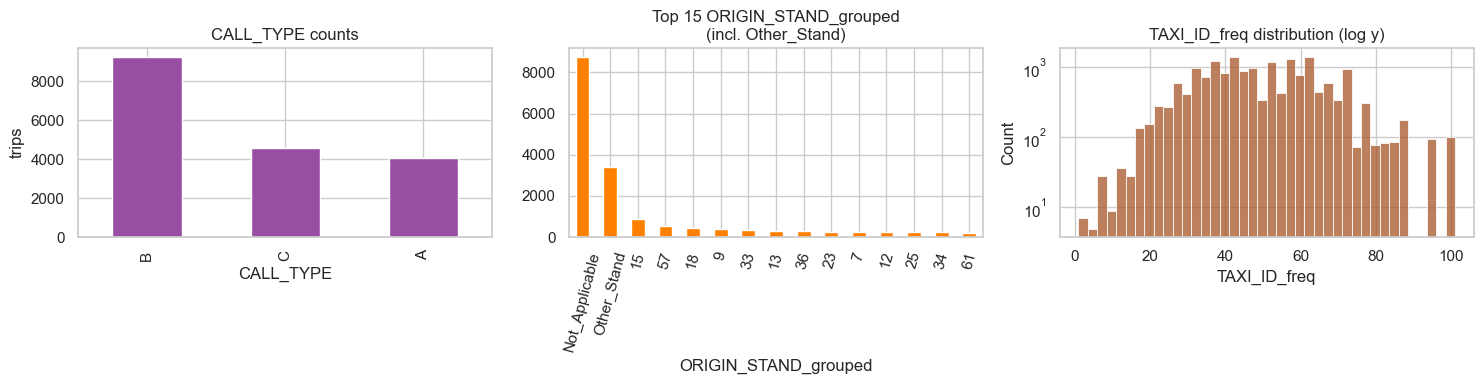

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

df["CALL_TYPE"].value_counts().plot.bar(ax=axes[0], color="#984ea3")
axes[0].set_title("CALL_TYPE counts"); axes[0].set_ylabel("trips")

df["ORIGIN_STAND_grouped"].value_counts().head(15).plot.bar(ax=axes[1], color="#ff7f00")
axes[1].set_title("Top 15 ORIGIN_STAND_grouped\n(incl. Other_Stand)"); axes[1].tick_params(axis="x", rotation=75)

sns.histplot(df["TAXI_ID_freq"], bins=40, ax=axes[2], color="#a65628")
axes[2].set_yscale("log"); axes[2].set_title("TAXI_ID_freq distribution (log y)")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/04_encoding.png", dpi=120); plt.show()


In [8]:
freq_per_taxi = df["TAXI_ID_freq"].drop_duplicates().sort_values(ascending=False)
n_taxis = len(freq_per_taxi)
top20_n = max(1, int(0.2 * n_taxis))
pareto_share = freq_per_taxi.head(top20_n).sum() / freq_per_taxi.sum()
print(f"top 20% of taxis ({top20_n}/{n_taxis}) account for {100*pareto_share:.1f}% of trips (Pareto check)")


top 20% of taxis (15/77) account for 34.1% of trips (Pareto check)


## 5. חוסר איזון DAY_TYPE

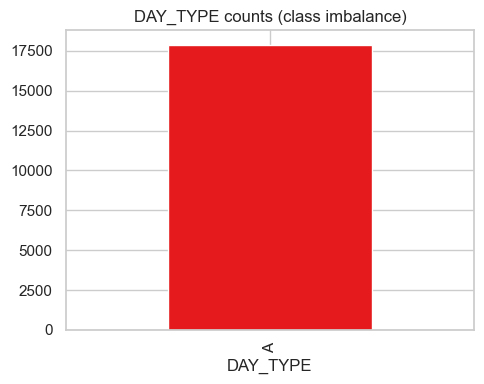

DAY_TYPE
A    17883
Name: count, dtype: int64

class_weight per DAY_TYPE:
DAY_TYPE
A    1.0
Name: class_weight, dtype: float64


In [9]:
fig, ax = plt.subplots(figsize=(5, 4))
df["DAY_TYPE"].value_counts().plot.bar(ax=ax, color="#e41a1c")
ax.set_title("DAY_TYPE counts (class imbalance)")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/05_day_type_imbalance.png", dpi=120); plt.show()

print(df["DAY_TYPE"].value_counts())
print("\nclass_weight per DAY_TYPE:")
print(df.groupby("DAY_TYPE")["class_weight"].first())


על המדגם (20K נסיעות) מופיע רק `DAY_TYPE='A'` — לכן `class_weight=1.0` (אין מה לאזן). על הדאטה המלא (1.71M נסיעות, שנה שלמה) עשויים להופיע גם B/C (חגים/חגי-ערב) בשיעור נמוך בהרבה — שם `undersample_majority`/`compute_class_weights` (סעיף 11 ב-`01_prep_clean.ipynb`) ייתנו תוצאה משמעותית בפועל.

## 6. בונוס — קורלציה בין פיצ'רי המסלול

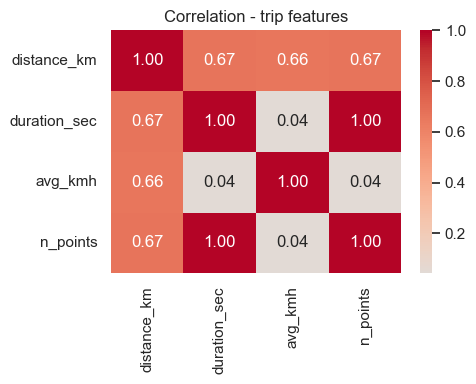

In [10]:
num_cols = ["distance_km", "duration_sec", "avg_kmh", "n_points"]
corr = df[num_cols].corr()
fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax)
ax.set_title("Correlation - trip features")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/06_correlation.png", dpi=120); plt.show()


## 7. שמירת טבלאות סיכום

In [11]:
outlier_df.to_csv("out/outlier_summary.csv", index=False)
stat_df.to_csv("out/skew_normality_summary.csv", index=False)
print("saved: out/outlier_summary.csv, out/skew_normality_summary.csv")
print("figures saved under:", FIG_DIR)


saved: out/outlier_summary.csv, out/skew_normality_summary.csv
figures saved under: out/figs
